# BiciLogic 02 · One courier, several deliveries (TSP)

**Goal.** A courier leaves a depot, must visit N delivery points and return. In what **order** should they visit so the total ride is shortest? This is the **Traveling Salesman Problem (TSP)**.

We solve it in two stages:

1. **Cost matrix** `D[i][j]` = real street-network distance between points `i` and `j`. Each cell is itself a shortest path (Dijkstra) over the graph.
2. **Order optimization** over `D`: exact (brute force) or heuristic (nearest neighbor, 2-opt, simulated annealing).

Key idea: once we have `D`, the problem stops talking about streets and becomes purely combinatorial over N+1 points.

## 1. Libraries and the Ixelles network

We reuse the `bike` network of Ixelles and **project it** to a metric CRS (meters), so that geometric projections and access distances below are correct. OSMnx caches downloads in `notebooks/cache/`, so re-runs are instant.

In [1]:
import sys
sys.path.append("../src")

import osmnx as ox
import networkx as nx
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point

from geo_utils import add_access_node, distance_matrix

ox.settings.use_cache = True

G = ox.graph_from_place("Ixelles, Brussels, Belgium", network_type="bike", simplify=True)
Gp = ox.project_graph(G)          # projected graph, coordinates in meters
crs = Gp.graph["crs"]
print(Gp)
print("CRS:", crs)

MultiDiGraph with 1111 nodes and 2439 edges
CRS: EPSG:32631


## 2. Depot and delivery points

Defined as `(lat, lon)` coordinates. **Provisional** (later we anchor them to real demand signals). We convert them to the projected CRS to work in meters.

In [2]:
depot = (50.8275, 4.3720)               # (lat, lon)
deliveries = [
    (50.8205, 4.3851),
    (50.8335, 4.3668),
    (50.8240, 4.3790),
    (50.8180, 4.3700),
    (50.8300, 4.3620),
]
labels = ["depot"] + [f"d{i+1}" for i in range(len(deliveries))]
points = [depot] + deliveries

# Project to meters (note: GeoDataFrame wants (lon, lat) = (x, y))
gdf = gpd.GeoDataFrame(
    geometry=[Point(lon, lat) for lat, lon in points], crs="EPSG:4326"
).to_crs(crs)
xs = gdf.geometry.x.values
ys = gdf.geometry.y.values

## 3. The snapping problem

A delivery coordinate rarely sits on a graph node. It can land:

- **(a) on a node** - ideal;
- **(b) in the middle of an edge** - snapping to the nearest *node* can be a bad approximation if the edge is long, and it forces an arbitrary choice of which endpoint to enter from;
- **(c) off the street graph** - the point is simply far from any street.

The right fix is to snap to the nearest **edge**, project the point onto it, and insert a *virtual node* at the projection that splits the edge (respecting one-way direction). Then the router decides on its own which endpoint to use.

Two useful facts:
- the perpendicular **access 'stub'** (off-network distance) is entered and left once per stop -> a *per-point constant* that does **not** change the optimal order, only the reported total;
- what *does* change the order is the **endpoint choice**, which the virtual node handles automatically.

In [3]:
# Method A (naive): snap to nearest node.
nodesA = ox.nearest_nodes(Gp, X=xs, Y=ys)

# Diagnostic: how far is each point from a node vs from the nearest edge?
_, dist_node = ox.distance.nearest_nodes(Gp, X=xs, Y=ys, return_dist=True)
_, dist_edge = ox.distance.nearest_edges(Gp, X=xs, Y=ys, return_dist=True)
diag = pd.DataFrame(
    {"to_nearest_node_m": np.round(dist_node, 1),
     "to_nearest_edge_m": np.round(dist_edge, 1)},
    index=labels,
)
print("A point far from the nearest node but close to an edge sits mid-edge")
print("(and a large stub means the point is essentially off the bike network):")
diag

A point far from the nearest node but close to an edge sits mid-edge
(and a large stub means the point is essentially off the bike network):


,to_nearest_node_m,to_nearest_edge_m
depot,21.0,10.7
d1,1.8,0.2
d2,12.6,11.3
d3,22.8,16.6
d4,319.2,319.2
d5,155.2,146.8


In [4]:
# Method B (correct): insert a virtual access node on the nearest edge.
# Use negative ids so they never clash with OSM node ids.
GB = Gp.copy()
nodesB, stubs = [], []
for i, (x, y) in enumerate(zip(xs, ys)):
    nid, stub = add_access_node(GB, x, y, node_id=-(i + 1))
    nodesB.append(nid)
    stubs.append(stub)

print("Access stub (m) per point (per-point constant):")
print(pd.Series(np.round(stubs, 1), index=labels).to_string())

Access stub (m) per point (per-point constant):
depot     10.7
d1         0.2
d2        11.3
d3        16.6
d4       319.2
d5       146.8


## 4. Distance matrices and comparison

For each origin we run a single Dijkstra that gets distances to *all* nodes at once (`single_source_dijkstra_path_length`), then keep the columns we need. The graph is **directed** (one-way streets), so `D[i][j] != D[j][i]` in general - an **asymmetric** TSP.

In [5]:
DA = distance_matrix(Gp, nodesA)      # nearest-node
DB = distance_matrix(GB, nodesB)      # virtual access node

print("Matrix B (virtual access node), meters:")
display(pd.DataFrame(DB, index=labels, columns=labels).round(0))

diff = DB - DA
print("How much the correct snapping changes the matrix (B - A), meters:")
display(pd.DataFrame(diff, index=labels, columns=labels).round(0))
print("max |B-A| =", round(float(np.nanmax(np.abs(diff))), 1),
      "   mean |B-A| =", round(float(np.nanmean(np.abs(diff))), 1))

# We keep DB as the matrix for the optimizer.
D = DB

Matrix B (virtual access node), meters:


,depot,d1,d2,d3,d4,d5
depot,0.0,1450.0,1018.0,949.0,981.0,1328.0
d1,1589.0,0.0,2161.0,623.0,1168.0,2471.0
d2,797.0,2247.0,0.0,1746.0,1729.0,460.0
d3,1235.0,801.0,1808.0,0.0,909.0,2118.0
d4,981.0,1409.0,1917.0,1101.0,0.0,2227.0
d5,908.0,2358.0,509.0,1856.0,1840.0,0.0


How much the correct snapping changes the matrix (B - A), meters:


,depot,d1,d2,d3,d4,d5
depot,0.0,19.0,-31.0,-30.0,44.0,-43.0
d1,7.0,0.0,-0.0,-45.0,2.0,-12.0
d2,5.0,25.0,0.0,-25.0,-0.0,-8.0
d3,-41.0,133.0,-48.0,0.0,-24.0,-60.0
d4,44.0,-1.0,-2.0,-24.0,0.0,-13.0
d5,19.0,39.0,12.0,-11.0,13.0,0.0


max |B-A| = 132.6    mean |B-A| = 21.6


## 5. Visualize the stops

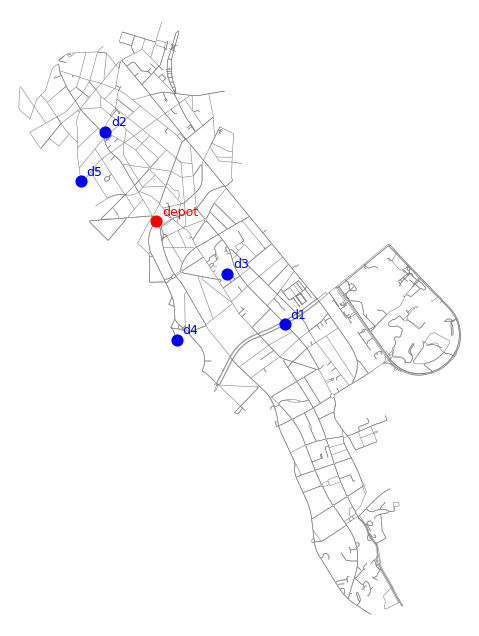

In [6]:
fig, ax = ox.plot_graph(Gp, node_size=0, edge_linewidth=0.4, edge_color="gray",
                        bgcolor="white", show=False, close=False)
for lab, n in zip(labels, nodesB):
    x, y = GB.nodes[n]["x"], GB.nodes[n]["y"]
    color = "red" if lab == "depot" else "blue"
    ax.scatter(x, y, c=color, s=60, zorder=5)
    ax.annotate(lab, (x, y), color=color, fontsize=9,
                xytext=(4, 4), textcoords="offset points")
plt.show()

## 6. Solving the visit order (small instance)

Now that `D` is ready, the problem is purely combinatorial. We compare three references:

- **naive** - visit stops in input order (a baseline to beat);
- **nearest neighbor** - greedy heuristic: always go to the closest unvisited stop;
- **brute-force optimal** - try every permutation. Exact, but costs `(n-1)!`, so it is ground truth only for small n.

In [7]:
from tsp import (tour_distance, naive_order, nearest_neighbor,
                 brute_force_optimal, two_opt, simulated_annealing)

def show(name, order):
    seq = " -> ".join(labels[i] for i in order + [order[0]])
    print(f"{name:18s} {tour_distance(D, order):8.0f} m   {seq}")

show("naive (input)", naive_order(len(D)))
show("nearest neighbor", nearest_neighbor(D, start=0))
best, cost = brute_force_optimal(D, depot=0)
show("brute-force OPT", best)

naive (input)          9401 m   depot -> d1 -> d2 -> d3 -> d4 -> d5 -> depot
nearest neighbor       6202 m   depot -> d3 -> d1 -> d4 -> d2 -> d5 -> depot
brute-force OPT        6189 m   depot -> d4 -> d1 -> d3 -> d2 -> d5 -> depot


## 7. Scaling up: 2-opt and simulated annealing

Brute force dies at ~10-12 stops (`(n-1)!`). We need heuristics that scale.

**2-opt** is local search: cut two edges, reverse the segment between them, keep the move if it shortens the tour; stop when nothing improves. Like gradient descent, it gets stuck in **local minima**.

**Simulated annealing** is the *Metropolis algorithm*. Map the problem to physics: a **state** is a tour, its **energy** `E` is the tour length, and we want the ground state (global minimum). Propose a random 2-opt move with energy change `dE`; accept it if `dE <= 0`, else accept it anyway with probability `exp(-dE / T)`. A high **temperature** `T` explores freely (accepts uphill moves); cooling `T <- alpha * T` turns it greedy. Those uphill moves are what let it escape the local minima that trap 2-opt.

In [8]:
# Sanity check on the small instance: both heuristics should reach the known optimum.
nn5 = nearest_neighbor(D)
o2, c2 = two_opt(D, nn5)
sa, csa, _ = simulated_annealing(D, nn5, seed=1)
print(f"optimum (brute force): {cost:8.0f}")
print(f"2-opt:                 {c2:8.0f}")
print(f"annealing:             {csa:8.0f}")

optimum (brute force):     6189


2-opt:                     6189
annealing:                 6189


A larger instance is where it matters. We sample 15 random delivery nodes from the **largest strongly connected component** (so every pair is reachable on the directed graph); `15!` permutations make brute force hopeless.

In [9]:
scc = max(nx.strongly_connected_components(Gp), key=len)
Gs = Gp.subgraph(scc).copy()
rng = np.random.default_rng(42)
chosen = list(rng.choice(list(Gs.nodes), size=16, replace=False))
Dbig = distance_matrix(Gs, chosen)

nn_b = nearest_neighbor(Dbig)
o2_b, c2_b = two_opt(Dbig, nn_b)
sa_b, csa_b, hist = simulated_annealing(Dbig, nn_b, seed=1)

print(f"naive (random order): {tour_distance(Dbig, naive_order(len(Dbig))):8.0f} m")
print(f"nearest neighbor:     {tour_distance(Dbig, nn_b):8.0f} m")
print(f"2-opt (from NN):      {c2_b:8.0f} m")
print(f"annealing:            {csa_b:8.0f} m")

naive (random order):    28402 m
nearest neighbor:        14060 m
2-opt (from NN):         14060 m
annealing:               12498 m


Typically 2-opt stalls at (or very near) the nearest-neighbor tour - a **local minimum** - while annealing's uphill moves find a clearly shorter tour. (Plain 2-opt is also weaker on *asymmetric* matrices, since reversing a segment flips its direction of travel.)

The convergence curve shows the mechanism: while hot, the *current* tour bounces up and down (accepting uphill moves); as it cools, it settles, and *best* ratchets down.

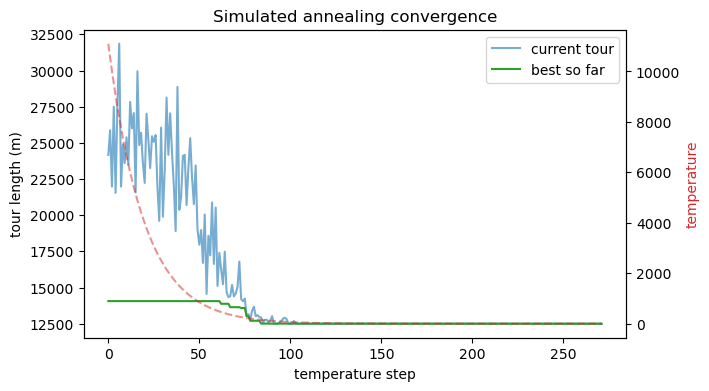

In [10]:
T_arr = [h[0] for h in hist]
cur_arr = [h[1] for h in hist]
best_arr = [h[2] for h in hist]

fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(cur_arr, color="tab:blue", alpha=0.6, label="current tour")
ax1.plot(best_arr, color="tab:green", label="best so far")
ax1.set_xlabel("temperature step")
ax1.set_ylabel("tour length (m)")
ax1.legend(loc="upper right")
ax2 = ax1.twinx()
ax2.plot(T_arr, color="tab:red", ls="--", alpha=0.5)
ax2.set_ylabel("temperature", color="tab:red")
plt.title("Simulated annealing convergence")
plt.show()

## Summary

- A correct geospatial pipeline: real network -> robust point snapping -> asymmetric distance matrix.
- A single-courier route optimizer: naive / nearest-neighbor / 2-opt / simulated annealing, validated against the exact optimum on small instances.

**Next (notebook 03):** several couriers - splitting the stops among them and balancing workload (the Vehicle Routing Problem).